## 0_Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# formats all floats to two decimal places
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## **1_Dataset 1**

### 1.0_Import and Inspect Dataset

In [3]:
google_df1 = pd.read_csv('googleplaystore.csv')
google_df1.head(2)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.90,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up


### 1.1_Basic Inspection

In [4]:
google_df1.shape

(10841, 13)

In [5]:
google_df1.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='object')

In [6]:
google_df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


Findings:
1) Some column data types need to be revised, namely:
- Reviews | object --> Reviews | int
- Size | object --> Size | float
- Installs | object --> Installs | int
- Price | object --> Price | float
- Last Updated | object --> Last Updated | datetime

2) Some column names should be concatenated or spaces should be replaced with an underscore (_) 

In [7]:
google_df1.isna().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Findings: The Rating column has the most missing data but is still valid since it only equates to around 13.60%

In [8]:
google_df1.describe()
# Revisit once the other columns are converted to numerical columns

,Rating
count,"9,367.00"
mean,4.19
std,0.54
min,1.00
25%,4.00
50%,4.30
75%,4.50
max,19.00


### 1.2_Create a Copy of `google_df1`

In [9]:
google_df1_copy = google_df1.copy()
google_df1_copy.head(2)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.90,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up


### 1.3_Editing Columns

In [10]:
# Concatenate columns with spaces
google_df1_copy = google_df1_copy.rename(columns=lambda x: x.replace(' ', ''))

# Rename column/s
google_df1_copy = google_df1_copy.rename(columns={"App": "AppName", "Reviews": "ReviewCount", "Size": "Size_MB", "AndroidVer": "MinAndroidVer"})

google_df1_copy.head(2) # test

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,Genres,LastUpdated,CurrentVer,MinAndroidVer
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.90,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up


In [11]:
# Remove irrelevant columns
google_df1_copy = google_df1_copy[['AppName', 'Category', 'Rating', 'ReviewCount', 'Size_MB', 'Installs',
       'Type', 'Price', 'ContentRating', #'Genres',
       'LastUpdated', #'CurrentVer',
       'MinAndroidVer']]

google_df1_copy.head(2)

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,19M,"10,000+",Free,0,Everyone,"January 7, 2018",4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.90,967,14M,"500,000+",Free,0,Everyone,"January 15, 2018",4.0.3 and up


In [12]:
# Adjust row 10474 since the values are out of place
google_df1_copy.iloc[10472, 3:] = google_df1_copy.iloc[10472, 3:].shift(1)

google_df1_copy.iloc[10472] # test

AppName          Life Made WI-Fi Touchscreen Photo Frame
Category                                             1.9
Rating                                             19.00
ReviewCount                                         None
Size_MB                                             3.0M
Installs                                          1,000+
Type                                                Free
Price                                                  0
ContentRating                                   Everyone
LastUpdated                                          NaN
MinAndroidVer                                     1.0.19
Name: 10472, dtype: object

*Column Name: **Size_MB***

In [13]:
# Convert KB sized apps to MB
def convert_size_to_mb(val):
    if pd.isna(val):
        return np.nan
    
    val = str(val).strip()
    
    # Convert KB to MB (divide by 1000 or 1024 depending on preference)
    if val.lower().endswith('k'):
        return float(val[:-1]) / 1000  # Use 1024 for binary megabytes (MiB)
    
    # Strip 'M' for MB values and convert to float
    if val.lower().endswith('m'):
        return float(val[:-1])
    
    # Handle direct numeric inputs or non-standard text
    try:
        return float(val)
    except ValueError:
        return np.nan


# Apply the function to the 'Size' column
google_df1_copy['Size_MB'] = google_df1_copy['Size_MB'].apply(convert_size_to_mb)

*Column Name: **Installs***

In [14]:
# Remove "+" and ","
google_df1_copy['Installs'] = google_df1_copy['Installs'].astype(str).str.replace(r'[+,]', '', regex=True)

*Column Name: **Type***

In [15]:
# Replace missing value for row index [9148]
match_idx = google_df1_copy.index[google_df1_copy['Type'].isna()].tolist() # to identify index value for this row

# Change the "NaN" value to "Free"
google_df1_copy.loc[google_df1_copy['AppName'] == 'Command & Conquer: Rivals', 'Type'] = "Free"

google_df1_copy.iloc[9148] # test

AppName          Command & Conquer: Rivals
Category                            FAMILY
Rating                                 NaN
ReviewCount                              0
Size_MB                                NaN
Installs                                 0
Type                                  Free
Price                                    0
ContentRating                 Everyone 10+
LastUpdated                  June 28, 2018
MinAndroidVer           Varies with device
Name: 9148, dtype: object

*Column Name: **Price***

In [16]:
# Remove "$" symbol
google_df1_copy['Price'] = google_df1_copy['Price'].astype(str).str.replace(r'[$]', '', regex=True)

*Column Name: **MinAndroidVer***

In [17]:
# Remove "and up", "-", and max android version
google_df1_copy['MinAndroidVer'] = (google_df1_copy['MinAndroidVer'].astype(str).str.replace(r'\s*and up|\s*-.*', '', regex=True).str.strip())

In [18]:
# Used to repeatedly check missing data while editing rows and columns
google_df1_copy.isna().sum()

AppName             0
Category            0
Rating           1474
ReviewCount         1
Size_MB          1695
Installs            0
Type                0
Price               0
ContentRating       0
LastUpdated         1
MinAndroidVer       0
dtype: int64

### 1.4_Correcting Data Types

In [19]:
google_df1_copy.info() # check revised data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   AppName        10841 non-null  object 
 1   Category       10841 non-null  object 
 2   Rating         9367 non-null   float64
 3   ReviewCount    10840 non-null  object 
 4   Size_MB        9146 non-null   float64
 5   Installs       10841 non-null  object 
 6   Type           10841 non-null  object 
 7   Price          10841 non-null  object 
 8   ContentRating  10841 non-null  object 
 9   LastUpdated    10840 non-null  object 
 10  MinAndroidVer  10841 non-null  object 
dtypes: float64(2), object(9)
memory usage: 931.8+ KB


In [20]:
# Convert `ReviewCount` from object to numeric
google_df1_copy['ReviewCount'] = pd.to_numeric(google_df1_copy['ReviewCount'], errors='coerce')

In [21]:
# Convert `Installs` from object to numeric
google_df1_copy['Installs'] = pd.to_numeric(google_df1_copy['Installs'], errors='coerce')

In [22]:
# Convert `Price` from object to numeric
google_df1_copy['Price'] = pd.to_numeric(google_df1_copy['Price'], errors='coerce')

In [23]:
# Convert `LastUpdated` from object to datetime
google_df1_copy['LastUpdated'] = pd.to_datetime(google_df1_copy['LastUpdated'], errors='coerce')

### 1.5_Checking for Duplicates

In [24]:
google_df1_copy.loc[google_df1_copy.duplicated()]

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
229,Quick PDF Scanner + OCR FREE,BUSINESS,4.20,"80,805.00",NaN,5000000,Free,0.00,Everyone,2018-02-26,4.0.3
236,Box,BUSINESS,4.20,"159,872.00",NaN,10000000,Free,0.00,Everyone,2018-07-31,Varies with device
239,Google My Business,BUSINESS,4.40,"70,991.00",NaN,5000000,Free,0.00,Everyone,2018-07-24,4.4
256,ZOOM Cloud Meetings,BUSINESS,4.40,"31,614.00",37.00,10000000,Free,0.00,Everyone,2018-07-20,4.0
261,join.me - Simple Meetings,BUSINESS,4.00,"6,989.00",NaN,1000000,Free,0.00,Everyone,2018-07-16,4.4
...,...,...,...,...,...,...,...,...,...,...,...
8643,Wunderlist: To-Do List & Tasks,PRODUCTIVITY,4.60,"404,610.00",NaN,10000000,Free,0.00,Everyone,2018-04-06,Varies with device
8654,"TickTick: To Do List with Reminder, Day Planner",PRODUCTIVITY,4.60,"25,370.00",NaN,1000000,Free,0.00,Everyone,2018-08-06,Varies with device
8658,ColorNote Notepad Notes,PRODUCTIVITY,4.60,"2,401,017.00",NaN,100000000,Free,0.00,Everyone,2018-06-27,Varies with device
10049,Airway Ex - Intubate. Anesthetize. Train.,MEDICAL,4.30,123.00,86.00,10000,Free,0.00,Everyone,2018-06-01,5.0


In [25]:
# Checking an example duplicate
google_df1_copy.query('AppName == "Quick PDF Scanner + OCR FREE"')

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
222,Quick PDF Scanner + OCR FREE,BUSINESS,4.20,"80,805.00",NaN,5000000,Free,0.00,Everyone,2018-02-26,4.0.3
229,Quick PDF Scanner + OCR FREE,BUSINESS,4.20,"80,805.00",NaN,5000000,Free,0.00,Everyone,2018-02-26,4.0.3
285,Quick PDF Scanner + OCR FREE,BUSINESS,4.20,"80,804.00",NaN,5000000,Free,0.00,Everyone,2018-02-26,4.0.3


In [26]:
google_df1_copy.columns

Index(['AppName', 'Category', 'Rating', 'ReviewCount', 'Size_MB', 'Installs',
       'Type', 'Price', 'ContentRating', 'LastUpdated', 'MinAndroidVer'],
      dtype='object')

In [27]:
# Display only non-duplicated rows
google_df1_copy = google_df1_copy.loc[~google_df1_copy.duplicated(subset=['AppName', 'Category', 'Rating', 'ReviewCount'])].reset_index(drop=True)

In [28]:
# Check if duplicated rows were dropped
google_df1_copy.shape

(10356, 11)

### 1.6_Handling Missing Values

In [29]:
# Recheck missing values after deleting duplicated rows
google_df1_copy.isna().sum()

AppName             0
Category            0
Rating           1465
ReviewCount         1
Size_MB          1526
Installs            0
Type                0
Price               0
ContentRating       0
LastUpdated         1
MinAndroidVer       0
dtype: int64

In [30]:
google_df1_copy.isna().any(axis=1).sum()

np.int64(2934)

In [31]:
google_df1_copy[google_df1_copy['Rating'].isna()]

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
23,Mcqueen Coloring pages,ART_AND_DESIGN,NaN,61.00,7.00,100000,Free,0.00,Everyone,2018-03-07,4.1
113,Wrinkles and rejuvenation,BEAUTY,NaN,182.00,5.70,100000,Free,0.00,Everyone 10+,2017-09-20,3.0
123,Manicure - nail design,BEAUTY,NaN,119.00,3.70,50000,Free,0.00,Everyone,2018-07-23,4.1
126,Skin Care and Natural Beauty,BEAUTY,NaN,654.00,7.40,100000,Free,0.00,Teen,2018-07-17,4.1
129,"Secrets of beauty, youth and health",BEAUTY,NaN,77.00,2.90,10000,Free,0.00,Mature 17+,2017-08-08,2.3
...,...,...,...,...,...,...,...,...,...,...,...
10339,Cardio-FR,MEDICAL,NaN,67.00,82.00,10000,Free,0.00,Everyone,2018-07-31,4.4
10340,Naruto & Boruto FR,SOCIAL,NaN,7.00,7.70,100,Free,0.00,Teen,2018-02-02,4.0
10346,payermonstationnement.fr,MAPS_AND_NAVIGATION,NaN,38.00,9.80,5000,Free,0.00,Everyone,2018-06-13,4.0
10350,FR Forms,BUSINESS,NaN,0.00,9.60,10,Free,0.00,Everyone,2016-09-29,4.0


In [32]:
google_df1_copy_complete = google_df1_copy.dropna()

google_df1_copy_complete.shape

(7422, 11)

In [33]:
print("Dataset 1")
print("Original rows:", len(google_df1_copy))
print("Rows after complete-case deletion", len(google_df1_copy_complete))
print("Rows removed:", len(google_df1_copy) - len(google_df1_copy_complete))

Dataset 1
Original rows: 10356
Rows after complete-case deletion 7422
Rows removed: 2934


In [34]:
# Check if there are still missing values
google_df1_copy_complete.isna().sum()

AppName          0
Category         0
Rating           0
ReviewCount      0
Size_MB          0
Installs         0
Type             0
Price            0
ContentRating    0
LastUpdated      0
MinAndroidVer    0
dtype: int64

In [35]:
# Check updated numeric values
google_df1_copy_complete.describe()

,Rating,ReviewCount,Size_MB,Installs,Price,LastUpdated
count,"7,422.00","7,422.00","7,422.00","7,422.00","7,422.00",7422
mean,4.17,"278,821.80",22.75,"7,823,331.41",1.12,2017-10-22 15:27:12.659660544
min,1.00,1.00,0.01,1.00,0.00,2010-05-21 00:00:00
25%,4.00,99.00,5.10,"10,000.00",0.00,2017-07-17 00:00:00
50%,4.30,"2,066.50",14.00,"100,000.00",0.00,2018-05-09 00:00:00
75%,4.50,"36,874.25",33.00,"1,000,000.00",0.00,2018-07-17 00:00:00
max,5.00,"44,893,888.00",100.00,"1,000,000,000.00",400.00,2018-08-08 00:00:00
std,0.55,"1,743,853.83",23.44,"46,310,331.69",17.71,NaN


## **2_Dataset 2**

### 2.0_Import and Inspect Dataset

In [36]:
google_df2 = pd.read_csv('Google-Playstore.csv')
google_df2.head(2)

,App Name,App Id,Category,Rating,Rating Count,Installs,Minimum Installs,Maximum Installs,Free,Price,...,Developer Website,Developer Email,Released,Last Updated,Content Rating,Privacy Policy,Ad Supported,In App Purchases,Editors Choice,Scraped Time
0,Gakondo,com.ishakwe.gakondo,Adventure,0.00,0.00,10+,10.00,15,True,0.00,...,https://beniyizibyose.tk/#/,jean21101999@gmail.com,"Feb 26, 2020","Feb 26, 2020",Everyone,https://beniyizibyose.tk/projects/,False,False,False,2021-06-15 20:19:35
1,Ampere Battery Info,com.webserveis.batteryinfo,Tools,4.40,64.00,"5,000+","5,000.00",7662,True,0.00,...,https://webserveis.netlify.app/,webserveis@gmail.com,"May 21, 2020","May 06, 2021",Everyone,https://dev4phones.wordpress.com/licencia-de-uso/,True,False,False,2021-06-15 20:19:35


### 2.1_Basic Inspection

In [37]:
google_df2.shape

(2312944, 24)

In [38]:
google_df2.columns

Index(['App Name', 'App Id', 'Category', 'Rating', 'Rating Count', 'Installs',
       'Minimum Installs', 'Maximum Installs', 'Free', 'Price', 'Currency',
       'Size', 'Minimum Android', 'Developer Id', 'Developer Website',
       'Developer Email', 'Released', 'Last Updated', 'Content Rating',
       'Privacy Policy', 'Ad Supported', 'In App Purchases', 'Editors Choice',
       'Scraped Time'],
      dtype='object')

In [39]:
google_df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2312944 entries, 0 to 2312943
Data columns (total 24 columns):
 #   Column             Dtype  
---  ------             -----  
 0   App Name           object 
 1   App Id             object 
 2   Category           object 
 3   Rating             float64
 4   Rating Count       float64
 5   Installs           object 
 6   Minimum Installs   float64
 7   Maximum Installs   int64  
 8   Free               bool   
 9   Price              float64
 10  Currency           object 
 11  Size               object 
 12  Minimum Android    object 
 13  Developer Id       object 
 14  Developer Website  object 
 15  Developer Email    object 
 16  Released           object 
 17  Last Updated       object 
 18  Content Rating     object 
 19  Privacy Policy     object 
 20  Ad Supported       bool   
 21  In App Purchases   bool   
 22  Editors Choice     bool   
 23  Scraped Time       object 
dtypes: bool(4), float64(4), int64(1), object(15)
memor

Findings:
1) Some column data types need to be revised, namely:
- Rating Count | float --> Rating Count | int
- Installs | object --> Installs | int
- Minimum Installs | float --> Installs | int
- Released | object --> Released | datetime
- Last Updated | object --> Last Updated | datetime

2) Some column names should be concatenated or spaces should be replaced with an underscore (_)

3) Remove some columns if not relevant to the study

In [40]:
google_df2.isna().sum()

App Name                  5
App Id                    0
Category                  0
Rating                22883
Rating Count          22883
Installs                107
Minimum Installs        107
Maximum Installs          0
Free                      0
Price                     0
Currency                135
Size                    196
Minimum Android        6530
Developer Id             33
Developer Website    760835
Developer Email          31
Released              71053
Last Updated              0
Content Rating            0
Privacy Policy       420953
Ad Supported              0
In App Purchases          0
Editors Choice            0
Scraped Time              0
dtype: int64

Findings:
- The columns "Developer Website" and "Developer Email" are not relevant to the project so even if they have the most missing data, these columns will be deleted anyway.
- "Released" column will also not be used for the project.
- The "Rating" and "Rating Count" columns have the most missing data but are still valid since they equate to less than 1%

In [41]:
google_df2.describe()
# Revisit once the other columns are converted to numerical columns

,Rating,Rating Count,Minimum Installs,Maximum Installs,Price
count,"2,290,061.00","2,290,061.00","2,312,837.00","2,312,944.00","2,312,944.00"
mean,2.20,"2,864.84","183,445.21","320,201.71",0.10
std,2.11,"212,162.57","15,131,439.06","23,554,954.89",2.63
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,50.00,84.00,0.00
50%,2.90,6.00,500.00,695.00,0.00
75%,4.30,42.00,"5,000.00","7,354.00",0.00
max,5.00,"138,557,570.00","10,000,000,000.00","12,057,627,016.00",400.00


### 2.2_Create a Copy of `google_df2`

In [42]:
google_df2_copy = google_df2.copy()
google_df2_copy.head() # test

,App Name,App Id,Category,Rating,Rating Count,Installs,Minimum Installs,Maximum Installs,Free,Price,...,Developer Website,Developer Email,Released,Last Updated,Content Rating,Privacy Policy,Ad Supported,In App Purchases,Editors Choice,Scraped Time
0,Gakondo,com.ishakwe.gakondo,Adventure,0.00,0.00,10+,10.00,15,True,0.00,...,https://beniyizibyose.tk/#/,jean21101999@gmail.com,"Feb 26, 2020","Feb 26, 2020",Everyone,https://beniyizibyose.tk/projects/,False,False,False,2021-06-15 20:19:35
1,Ampere Battery Info,com.webserveis.batteryinfo,Tools,4.40,64.00,"5,000+","5,000.00",7662,True,0.00,...,https://webserveis.netlify.app/,webserveis@gmail.com,"May 21, 2020","May 06, 2021",Everyone,https://dev4phones.wordpress.com/licencia-de-uso/,True,False,False,2021-06-15 20:19:35
2,Vibook,com.doantiepvien.crm,Productivity,0.00,0.00,50+,50.00,58,True,0.00,...,NaN,vnacrewit@gmail.com,"Aug 9, 2019","Aug 19, 2019",Everyone,https://www.vietnamairlines.com/vn/en/terms-an...,False,False,False,2021-06-15 20:19:35
3,Smart City Trichy Public Service Vehicles 17UC...,cst.stJoseph.ug17ucs548,Communication,5.00,5.00,10+,10.00,19,True,0.00,...,http://www.climatesmarttech.com/,climatesmarttech2@gmail.com,"Sep 10, 2018","Oct 13, 2018",Everyone,NaN,True,False,False,2021-06-15 20:19:35
4,GROW.me,com.horodyski.grower,Tools,0.00,0.00,100+,100.00,478,True,0.00,...,http://www.horodyski.com.pl,rmilekhorodyski@gmail.com,"Feb 21, 2020","Nov 12, 2018",Everyone,http://www.horodyski.com.pl,False,False,False,2021-06-15 20:19:35


### 2.3_Editing Columns

In [43]:
google_df2_copy.columns

Index(['App Name', 'App Id', 'Category', 'Rating', 'Rating Count', 'Installs',
       'Minimum Installs', 'Maximum Installs', 'Free', 'Price', 'Currency',
       'Size', 'Minimum Android', 'Developer Id', 'Developer Website',
       'Developer Email', 'Released', 'Last Updated', 'Content Rating',
       'Privacy Policy', 'Ad Supported', 'In App Purchases', 'Editors Choice',
       'Scraped Time'],
      dtype='object')

In [44]:
# Remove irrelevant columns
google_df2_copy = google_df2_copy[['App Name', #'App Id', 
                                   'Category', 'Rating', 'Rating Count', 'Installs',
       #'Minimum Installs', 'Maximum Installs',
       'Free', 'Price', 'Currency',
       'Size', 'Minimum Android', #'Developer Id', 'Developer Website', 'Developer Email', 'Released', 
       'Last Updated', 'Content Rating',
       #'Privacy Policy', 'Ad Supported', 'In App Purchases', 'Editors Choice', 'Scraped Time'
       ]]

google_df2_copy.head(2) # test

,App Name,Category,Rating,Rating Count,Installs,Free,Price,Currency,Size,Minimum Android,Last Updated,Content Rating
0,Gakondo,Adventure,0.00,0.00,10+,True,0.00,USD,10M,7.1 and up,"Feb 26, 2020",Everyone
1,Ampere Battery Info,Tools,4.40,64.00,"5,000+",True,0.00,USD,2.9M,5.0 and up,"May 06, 2021",Everyone


In [45]:
# Concatenate columns with spaces
google_df2_copy = google_df2_copy.rename(columns=lambda x: x.replace(' ', ''))

# Rename column/s
google_df2_copy = google_df2_copy.rename(columns={"RatingCount": "ReviewCount", "Size": "Size_MB", "MinimumAndroid": "MinAndroidVer"})

In [46]:
# Reordering columns for future concatenation
google_df2_copy = google_df2_copy[['AppName', 'Category', 'Rating', 'ReviewCount', 'Size_MB', 'Installs', 'Free',
       'Price', 'Currency', 'ContentRating', 'LastUpdated', 'MinAndroidVer']]

*Column Name: **Category***

In [47]:
# Capitalize all values, change "&" to "AND", and change white space to "_"
google_df2_copy['Category'] = (google_df2_copy['Category']).str.upper().str.replace('&', 'AND', regex=False).str.replace(' ', '_', regex=True)

*Column Name: **Size_MB***

In [48]:
# drop GB sized apps
GB_apps = google_df2_copy[google_df2_copy['Size_MB'].isin(['1.5G', '1.1G'])].index
google_df2_copy = google_df2_copy.drop(GB_apps)
google_df2_copy.shape

(2312934, 12)

In [49]:
def convert_to_mb(val):
    if pd.isna(val):
        return np.nan
    
    # 1. Strip spaces and remove commas
    val = str(val).strip().replace(',', '')
    
    try:
        # 2. Convert KB to MB (divide by 1000; or use 1024 for MiB)
        if val.lower().endswith('k'):
            return float(val[:-1]) / 1000
        
        # 3. Strip 'M' and convert MB values directly
        if val.lower().endswith('m'):
            return float(val[:-1])
        
        # 4. Handle values that are already numbers or non-standard text
        return float(val)
        
    except ValueError:
        return np.nan

# Apply the function to the 'Size_MB' column
google_df2_copy['Size_MB'] = google_df2_copy['Size_MB'].apply(convert_to_mb)

In [50]:
google_df2_copy.isna().sum()

AppName              5
Category             0
Rating           22883
ReviewCount      22883
Size_MB          74976
Installs           107
Free                 0
Price                0
Currency           135
ContentRating        0
LastUpdated          0
MinAndroidVer     6530
dtype: int64

*Column Name: **Installs***

In [51]:
# Remove "+" and ","
google_df2_copy['Installs'] = google_df2_copy['Installs'].astype(str).str.replace(r'[+,]', '', regex=True)

*Column Name: **Free***

In [52]:
# Initialize 'Type' column with NaN
google_df2_copy['Type'] = np.nan

# Set 'Free' where Price is 0, and 'Paid' where Price is greater than 0
google_df2_copy.loc[google_df2_copy['Price'] == 0, 'Type'] = 'Free'
google_df2_copy.loc[google_df2_copy['Price'] > 0, 'Type'] = 'Paid'

C:\Users\Dustin\AppData\Local\Temp\ipykernel_21644\2073086395.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Free' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  google_df2_copy.loc[google_df2_copy['Price'] == 0, 'Type'] = 'Free'


In [53]:
# Rearrange the columns and drop "Free" column
#google_df2_copy.columns

google_df2_copy = google_df2_copy[['AppName', 'Category', 'Rating', 'ReviewCount', 'Size_MB', 'Installs', 'Type',
       #'Free',
       'Price', 'Currency', 'ContentRating', 'LastUpdated', 'MinAndroidVer',
       ]]

In [54]:
google_df2_copy

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,Currency,ContentRating,LastUpdated,MinAndroidVer
0,Gakondo,ADVENTURE,0.00,0.00,10.00,10,Free,0.00,USD,Everyone,"Feb 26, 2020",7.1 and up
1,Ampere Battery Info,TOOLS,4.40,64.00,2.90,5000,Free,0.00,USD,Everyone,"May 06, 2021",5.0 and up
2,Vibook,PRODUCTIVITY,0.00,0.00,3.70,50,Free,0.00,USD,Everyone,"Aug 19, 2019",4.0.3 and up
3,Smart City Trichy Public Service Vehicles 17UC...,COMMUNICATION,5.00,5.00,1.80,10,Free,0.00,USD,Everyone,"Oct 13, 2018",4.0.3 and up
4,GROW.me,TOOLS,0.00,0.00,6.20,100,Free,0.00,USD,Everyone,"Nov 12, 2018",4.1 and up
...,...,...,...,...,...,...,...,...,...,...,...,...
2312939,大俠客—熱血歸來,ROLE_PLAYING,4.30,"16,775.00",77.00,100000,Free,0.00,USD,Teen,"Jun 01, 2021",4.1 and up
2312940,ORU Online,EDUCATION,0.00,0.00,44.00,100,Free,0.00,USD,Everyone,"Feb 02, 2018",4.1 and up
2312941,Data Structure,EDUCATION,0.00,0.00,29.00,100,Free,0.00,USD,Everyone,"Aug 19, 2018",5.0 and up
2312942,Devi Suktam,MUSIC_AND_AUDIO,3.50,8.00,10.00,1000,Free,0.00,USD,Everyone,"May 05, 2021",5.0 and up


*Column Name: **MinAndroidVer***

In [55]:
# Remove "and up", "-", and max android version
google_df2_copy['MinAndroidVer'] = (google_df2_copy['MinAndroidVer'].astype(str).str.replace(r'\s*and up|\s*-.*', '', regex=True).str.strip())

### 2.4 Correcting Data Types

In [56]:
# Convert `Installs` from object to numeric
google_df2_copy['Installs'] = pd.to_numeric(google_df2_copy['Installs'], errors='coerce')

In [57]:
google_df2_copy['Installs'] = google_df2_copy['Installs']

In [58]:
# Convert `LastUpdated` from object to datetime
google_df2_copy['LastUpdated'] = pd.to_datetime(google_df2_copy['LastUpdated'], errors='coerce')

In [59]:
# Used to repeatedly check missing data while editing rows and columns
google_df2_copy.isna().sum()

AppName              5
Category             0
Rating           22883
ReviewCount      22883
Size_MB          74976
Installs           107
Type                 0
Price                0
Currency           135
ContentRating        0
LastUpdated          0
MinAndroidVer        0
dtype: int64

In [60]:
google_df2_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2312934 entries, 0 to 2312943
Data columns (total 12 columns):
 #   Column         Dtype         
---  ------         -----         
 0   AppName        object        
 1   Category       object        
 2   Rating         float64       
 3   ReviewCount    float64       
 4   Size_MB        float64       
 5   Installs       float64       
 6   Type           object        
 7   Price          float64       
 8   Currency       object        
 9   ContentRating  object        
 10  LastUpdated    datetime64[ns]
 11  MinAndroidVer  object        
dtypes: datetime64[ns](1), float64(5), object(6)
memory usage: 229.4+ MB


### 2.5 Checking for Duplicates

In [61]:
google_df2_copy.loc[google_df2_copy.duplicated()]

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,Currency,ContentRating,LastUpdated,MinAndroidVer
185370,呆萌鸟2,CASUAL,0.00,0.00,13.00,1.00,Free,0.00,USD,Everyone,2019-12-21,4.1
235651,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,10.00,Free,0.00,USD,Mature 17+,2019-07-30,4.0.3
452411,EXCEL CLASSES,EDUCATION,0.00,0.00,37.00,1.00,Free,0.00,USD,Everyone,2021-06-09,4.2
488627,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,10.00,Free,0.00,USD,Mature 17+,2019-07-30,4.0.3
546688,ลูกหมู โมบาย - Look Moo Mobile,BUSINESS,0.00,0.00,2.30,1.00,Free,0.00,USD,Everyone,2019-04-30,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2244753,Myanmar Cook,NEWS_AND_MAGAZINES,0.00,0.00,3.80,10.00,Free,0.00,USD,Everyone,2018-11-08,2.3
2286836,VZ | Exprésate Lector Unidad 2,EDUCATION,0.00,0.00,54.00,10.00,Free,0.00,USD,Everyone,2019-04-15,5.0
2293112,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,10.00,Free,0.00,USD,Mature 17+,2019-07-29,4.0.3
2295473,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,10.00,Free,0.00,USD,Mature 17+,2019-07-31,4.0.3


In [62]:
# Checking an example duplicate
google_df2_copy.query('AppName == "Funny Memes Stickers for WhatsApp - WAStickerApps"')

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,Currency,ContentRating,LastUpdated,MinAndroidVer
111394,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,10.00,Free,0.00,USD,Mature 17+,2019-07-30,4.0.3
125810,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,10.00,Free,0.00,USD,Mature 17+,2019-08-02,4.0.3
235651,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,10.00,Free,0.00,USD,Mature 17+,2019-07-30,4.0.3
382221,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,50.00,Free,0.00,USD,Mature 17+,2019-07-31,4.0.3
450554,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,10.00,Free,0.00,USD,Mature 17+,2019-07-31,4.0.3
488627,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,10.00,Free,0.00,USD,Mature 17+,2019-07-30,4.0.3
566036,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,100.00,Free,0.00,USD,Mature 17+,2019-08-02,4.0.3
583943,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,5.00,Free,0.00,USD,Mature 17+,2019-08-02,4.0.3
755955,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,100.00,Free,0.00,USD,Mature 17+,2019-07-31,4.0.3
775325,Funny Memes Stickers for WhatsApp - WAStickerApps,COMMUNICATION,0.00,0.00,27.00,10.00,Free,0.00,USD,Mature 17+,2019-08-02,4.0.3


In [63]:
google_df2_copy.duplicated(subset=['AppName', 'Size_MB']).sum()

np.int64(11333)

In [64]:
# Display only non-duplicated rows
google_df2_copy = google_df2_copy.loc[~google_df2_copy.duplicated(subset=['AppName', 'Size_MB'])].reset_index(drop=True)

In [65]:
google_df2_copy.shape

(2301601, 12)

### 2.6_Handling Missing Values

In [66]:
# Recheck missing values after deleting duplicated rows
google_df2_copy.isna().sum()

AppName              5
Category             0
Rating           22645
ReviewCount      22645
Size_MB          74299
Installs           107
Type                 0
Price                0
Currency           135
ContentRating        0
LastUpdated          0
MinAndroidVer        0
dtype: int64

In [67]:
# Check total number of rows that have any missing data
google_df2_copy.isna().any(axis=1).sum()

np.int64(75281)

In [68]:
google_df2_copy_complete = google_df2_copy.dropna()

google_df2_copy_complete.shape # test

(2226320, 12)

### 2.7_Delete Apps That Are Not in USD

In [69]:
# Check all unique currencies
google_df2_copy_complete['Currency'].unique()

array(['USD', 'XXX', 'CAD', 'EUR', 'INR', 'VND', 'GBP', 'BRL', 'KRW',
       'TRY', 'SGD', 'AUD', 'ZAR'], dtype=object)

In [70]:
# Keep only rows where 'Currency' is equal to 'USD'
google_df2_copy_complete = google_df2_copy_complete[google_df2_copy_complete['Currency'] == 'USD']

# Reset the index after dropping rows
google_df2_copy_complete = google_df2_copy_complete.reset_index(drop=True)

In [71]:
# Drop Currency Column for concatenation later
google_df2_copy_complete = google_df2_copy_complete[['AppName', 'Category', 'Rating', 'ReviewCount', 'Size_MB', 'Installs', 'Type', 'Price', 'ContentRating', 'LastUpdated', 'MinAndroidVer']]
google_df2_copy_complete.head(2) # test

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
0,Gakondo,ADVENTURE,0.00,0.00,10.00,10.00,Free,0.00,Everyone,2020-02-26,7.1
1,Ampere Battery Info,TOOLS,4.40,64.00,2.90,"5,000.00",Free,0.00,Everyone,2021-05-06,5.0


In [72]:
google_df2_copy_complete.shape

(2225090, 11)

## **3_Concatenate Dataset 1 + Dataset 2**

In [73]:
applications = pd.concat([google_df1_copy_complete, google_df2_copy_complete], ignore_index=True)

### 3.1_Basic Inspection

In [74]:
applications.head()

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159.00,19.00,"10,000.00",Free,0.00,Everyone,2018-01-07,4.0.3
1,Coloring book moana,ART_AND_DESIGN,3.90,967.00,14.00,"500,000.00",Free,0.00,Everyone,2018-01-15,4.0.3
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,"87,510.00",8.70,"5,000,000.00",Free,0.00,Everyone,2018-08-01,4.0.3
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,"215,644.00",25.00,"50,000,000.00",Free,0.00,Teen,2018-06-08,4.2
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967.00,2.80,"100,000.00",Free,0.00,Everyone,2018-06-20,4.4


In [75]:
applications.tail()

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
2232507,大俠客—熱血歸來,ROLE_PLAYING,4.30,"16,775.00",77.00,"100,000.00",Free,0.00,Teen,2021-06-01,4.1
2232508,ORU Online,EDUCATION,0.00,0.00,44.00,100.00,Free,0.00,Everyone,2018-02-02,4.1
2232509,Data Structure,EDUCATION,0.00,0.00,29.00,100.00,Free,0.00,Everyone,2018-08-19,5.0
2232510,Devi Suktam,MUSIC_AND_AUDIO,3.50,8.00,10.00,"1,000.00",Free,0.00,Everyone,2021-05-05,5.0
2232511,Biliyor Musun - Sonsuz Yarış,TRIVIA,5.00,12.00,5.20,100.00,Free,0.00,Everyone,2019-08-19,5.0


In [76]:
applications.shape

(2232512, 11)

In [77]:
applications.columns

Index(['AppName', 'Category', 'Rating', 'ReviewCount', 'Size_MB', 'Installs',
       'Type', 'Price', 'ContentRating', 'LastUpdated', 'MinAndroidVer'],
      dtype='object')

In [78]:
applications.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2232512 entries, 0 to 2232511
Data columns (total 11 columns):
 #   Column         Dtype         
---  ------         -----         
 0   AppName        object        
 1   Category       object        
 2   Rating         float64       
 3   ReviewCount    float64       
 4   Size_MB        float64       
 5   Installs       float64       
 6   Type           object        
 7   Price          float64       
 8   ContentRating  object        
 9   LastUpdated    datetime64[ns]
 10  MinAndroidVer  object        
dtypes: datetime64[ns](1), float64(5), object(5)
memory usage: 187.4+ MB


In [79]:
applications.isna().sum()

AppName          0
Category         0
Rating           0
ReviewCount      0
Size_MB          0
Installs         0
Type             0
Price            0
ContentRating    0
LastUpdated      0
MinAndroidVer    0
dtype: int64

In [80]:
applications.describe()

,Rating,ReviewCount,Size_MB,Installs,Price,LastUpdated
count,"2,232,512.00","2,232,512.00","2,232,512.00","2,232,512.00","2,232,512.00",2232512
mean,2.19,"2,921.59",19.24,"134,295.60",0.11,2019-11-30 02:09:01.437089792
min,0.00,0.00,0.00,0.00,0.00,2009-02-09 00:00:00
25%,0.00,0.00,4.90,50.00,0.00,2019-04-06 00:00:00
50%,2.90,6.00,10.00,500.00,0.00,2020-05-11 00:00:00
75%,4.30,40.00,25.00,"5,000.00",0.00,2021-02-03 00:00:00
max,5.00,"56,025,424.00","1,020.00","1,000,000,000.00",400.00,2021-06-16 00:00:00
std,2.11,"134,371.95",23.91,"4,566,025.78",2.84,NaN


### 3.2_Column Inspection

*Column Name: **Categories***

In [81]:
# Check unique values under 'Categories' to know if some are similar
applications['Category'].unique()

array(['ART_AND_DESIGN', 'AUTO_AND_VEHICLES', 'BEAUTY',
       'BOOKS_AND_REFERENCE', 'BUSINESS', 'COMICS', 'COMMUNICATION',
       'DATING', 'EDUCATION', 'ENTERTAINMENT', 'EVENTS', 'FINANCE',
       'FOOD_AND_DRINK', 'HEALTH_AND_FITNESS', 'HOUSE_AND_HOME',
       'LIBRARIES_AND_DEMO', 'LIFESTYLE', 'GAME', 'FAMILY', 'MEDICAL',
       'SOCIAL', 'SHOPPING', 'PHOTOGRAPHY', 'SPORTS', 'TRAVEL_AND_LOCAL',
       'TOOLS', 'PERSONALIZATION', 'PRODUCTIVITY', 'PARENTING', 'WEATHER',
       'VIDEO_PLAYERS', 'NEWS_AND_MAGAZINES', 'MAPS_AND_NAVIGATION',
       'ADVENTURE', 'RACING', 'PUZZLE', 'ARCADE', 'BOARD',
       'MUSIC_AND_AUDIO', 'EDUCATIONAL', 'CASUAL', 'CARD', 'TRIVIA',
       'STRATEGY', 'WORD', 'VIDEO_PLAYERS_AND_EDITORS', 'ACTION',
       'SIMULATION', 'MUSIC', 'ROLE_PLAYING', 'CASINO'], dtype=object)

In [82]:
# Combine similar categories (ie: Education vs Educational)

# Mapping of old category names to new target names
category_mapping = {
    'MUSIC': 'MUSIC_AND_AUDIO',
    'VIDEO_PLAYERS': 'VIDEO_PLAYERS_AND_EDITORS',
    'EDUCATIONAL': 'EDUCATION',
    'PARENTING': 'FAMILY',
    'ARCADE': 'GAME'
}

# Apply replacement to the Category column
applications['Category'] = applications['Category'].replace(category_mapping)

*Column Name: **Type***

In [83]:
# Check unique values under 'Type' to know if some are similar
applications['Type'].unique()

array(['Free', 'Paid'], dtype=object)

*Column Name: **ContentRating***

In [84]:
# Check unique values under 'ContentRating' to know if some are similar
applications['ContentRating'].unique()

array(['Everyone', 'Teen', 'Everyone 10+', 'Mature 17+',
       'Adults only 18+', 'Unrated'], dtype=object)

### 3.3_Checking for Duplicates

In [85]:
applications.duplicated(subset=['AppName', 'Installs', 'ContentRating']).sum()

np.int64(32651)

In [86]:
# Display only non-duplicated rows
applications = applications.loc[~applications.duplicated(subset=['AppName', 'Installs', 'ContentRating'])].reset_index(drop=True)

### 3.4_Export Cleaned and Concatenated Dataset as CSV files - `Applications_Compiled`

In [87]:
applications.to_csv('Applications_Compiled.csv', index=False)

## **4_Exploratory Data Analysis**

### 4.1_Objective 1: Identify the highest rated apps

In [88]:
# Filter for apps with significant user backing (e.g., at least 10,000 reviews)
top_apps = applications[applications['ReviewCount'] >= 10000000].nlargest(15, 'Rating')
top_apps

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
356065,Video Editor & Video Maker - InShot,PHOTOGRAPHY,4.80,"10,680,340.00",59.00,"100,000,000.00",Free,0.00,Everyone,2021-06-11,5.0
1709125,Mercado Libre: compra fácil y rápido,SHOPPING,4.80,"12,337,949.00",33.00,"100,000,000.00",Free,0.00,Everyone,2021-06-11,5.0
968,Clash Royale,GAME,4.60,"23,133,508.00",97.00,"100,000,000.00",Free,0.00,Everyone 10+,2018-06-27,4.1
978,Clash of Clans,GAME,4.60,"44,891,723.00",98.00,"100,000,000.00",Free,0.00,Everyone 10+,2018-07-15,4.1
1106,Shadow Fight 2,GAME,4.60,"10,979,062.00",88.00,"100,000,000.00",Free,0.00,Everyone 10+,2018-07-02,3.0
1231098,"Safe Security - Antivirus, Booster, Phone Cle...",TOOLS,4.60,"16,783,533.00",26.00,"100,000,000.00",Free,0.00,Everyone,2020-06-18,4.1
1734171,AliExpress,SHOPPING,4.60,"11,805,765.00",99.00,"100,000,000.00",Free,0.00,Teen,2021-05-27,5.0
2042284,Wish - Shopping Made Fun,SHOPPING,4.60,"12,955,678.00",27.00,"500,000,000.00",Free,0.00,Teen,2021-06-10,5.0
248,UC Browser - Fast Download Private & Secure,COMMUNICATION,4.50,"17,712,922.00",40.00,"500,000,000.00",Free,0.00,Teen,2018-08-02,4.0
963,Subway Surfers,GAME,4.50,"27,722,264.00",76.00,"1,000,000,000.00",Free,0.00,Everyone 10+,2018-07-12,4.1


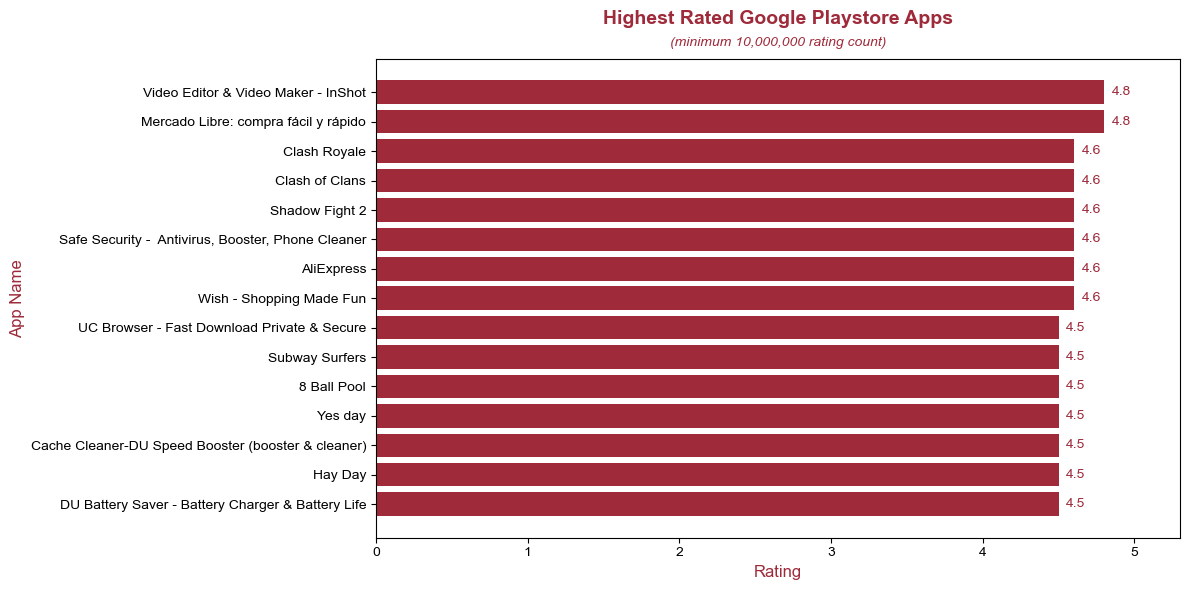

In [89]:
plt.rcParams['font.sans-serif'] = ['Arial']

app_names = top_apps['AppName']
ratings = top_apps['Rating']

plt.figure(figsize=(12, 6))

plt.barh(app_names, ratings, color='#9E2A3A')
plt.gca().invert_yaxis()
plt.xlim(0, 5.3)

plt.xlabel('Rating', fontsize=12, color='#9E2A3A')
plt.ylabel('App Name', fontsize=12, color='#9E2A3A')

# 1. Main Title centered over the plot box
plt.title('Highest Rated Google Playstore Apps',
          fontname='Arial',
          fontsize=14,
          fontweight='bold',
          color='#9E2A3A',
          pad=25)  # Creates vertical padding between title and chart top

# 2. Subtitle centered over the plot box using axes coordinates (0.5 = middle)
plt.gca().text(0.5, 1.02, '(minimum 10,000,000 rating count)',
               transform=plt.gca().transAxes,
               ha='center', va='bottom',
               fontname='Arial',
               fontsize=10,
               fontstyle='italic',
               color='#9E2A3A')

# Add bar labels
for i, value in enumerate(ratings):
    plt.text(value + 0.05, i, f'{value:.1f}', va='center',
             fontname='Arial', fontsize=10, color='#9E2A3A')

plt.tight_layout()
plt.show()

### 4.2_Objective 2: Rank categories by rating

In [90]:
# number of apps per category
cat_count = applications.groupby('Category')['AppName'].count()

# choose a filter to identify the top categories in terms of rating
cat_count.agg(['mean', 'median'])

mean     47,823.07
median   28,124.00
Name: AppName, dtype: float64

In [91]:
# Identify categories that have at least 28,109 total apps
eligible_categories = applications['Category'].value_counts()
eligible_categories = eligible_categories[eligible_categories >= 28109].index

# Filter dataset for apps with >= 10,000,000 reviews and in eligible categories
filtered_apps = applications[
    (applications['ReviewCount'] >= 10000000) & 
    (applications['Category'].isin(eligible_categories))
]

# Calculate average rating per category and retrieve top 10
top_10_categories = (
    filtered_apps
    .groupby('Category')['Rating']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_10_categories
# Only 9 categories satisfy the requirements

Category
PHOTOGRAPHY     4.80
SHOPPING        4.60
COMMUNICATION   4.50
GAME            4.46
SPORTS          4.45
TOOLS           4.45
SOCIAL          4.35
CASUAL          4.32
PRODUCTIVITY    4.20
Name: Rating, dtype: float64

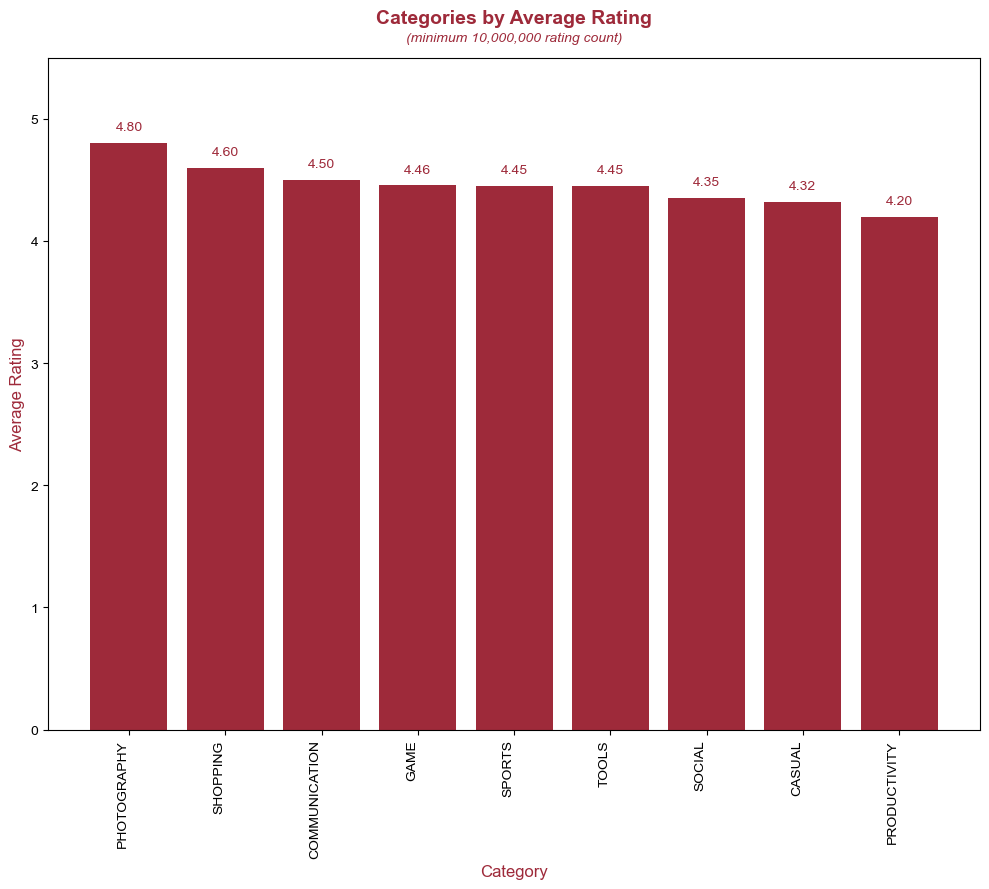

In [92]:
plt.rcParams['font.sans-serif'] = ['Arial']

# Create vertical bar chart figure
plt.figure(figsize=(10, 9))

# Plot vertical bars using the top_10_categories Series
bars = plt.bar(
    top_10_categories.index,
    top_10_categories.values,
    color='#9E2A3A'
)

# Set Y-axis limits (0 to 5.5) to leave room above the bars for text labels
plt.ylim(0, 5.5)

# Axis labels
plt.xlabel('Category', fontsize=12, color='#9E2A3A')
plt.ylabel('Average Rating', fontsize=12, color='#9E2A3A')

# Main Title
plt.title('Categories by Average Rating',
          fontname='Arial',
          fontsize=14,
          fontweight='bold',
          color='#9E2A3A',
          pad=25)

# Subtitle specifying the applied criteria
plt.gca().text(0.5, 1.02, '(minimum 10,000,000 rating count)',
               transform=plt.gca().transAxes,
               ha='center', va='bottom',
               fontname='Arial',
               fontsize=10,
               fontstyle='italic',
               color='#9E2A3A')

# Rotate category names so long titles like VIDEO_PLAYERS_AND_EDITORS don't overlap
plt.xticks(rotation=90, ha='right', fontsize=10)

# Add exact rating values on top of each vertical bar
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0,  # Center over the bar
             height + 0.08,                        # Position slightly above bar height
             f'{height:.2f}',                      # Format rating to 2 decimal places
             ha='center',
             va='bottom',
             fontname='Arial',
             fontsize=10,
             color='#9E2A3A')

plt.tight_layout()
plt.show()

### 4.3_Objective 3: Identifly the most installed apps

In [93]:
# top 20 most installed apps
most_installed = applications.sort_values('Installs', ascending=False).head(20)
most_installed = most_installed.sort_values('Rating', ascending=True)
most_installed

,AppName,Category,Rating,ReviewCount,Size_MB,Installs,Type,Price,ContentRating,LastUpdated,MinAndroidVer
188174,Samsung Health,HEALTH_AND_FITNESS,3.60,"1,244,210.00",85.00,"1,000,000,000.00",Free,0.00,Everyone,2021-05-17,8.0
406996,Briefing,NEWS_AND_MAGAZINES,3.90,"660,738.00",18.00,"1,000,000,000.00",Free,0.00,Everyone 10+,2021-06-08,5.0
2122,Google News,NEWS_AND_MAGAZINES,3.90,"877,635.00",13.00,"1,000,000,000.00",Free,0.00,Teen,2018-08-01,4.4
489939,ANT Radio Service,COMMUNICATION,4.00,"319,393.00",0.16,"1,000,000,000.00",Free,0.00,Everyone,2020-06-15,2.1
2165822,Samsung Print Service Plugin,PRODUCTIVITY,4.10,"430,733.00",43.00,"1,000,000,000.00",Free,0.00,Everyone,2021-06-07,4.4
1177691,Samsung Security Policy Update,PRODUCTIVITY,4.20,"304,658.00",0.75,"1,000,000,000.00",Free,0.00,Everyone,2020-09-09,4.1
707767,SHAREit - Transfer & Share,TOOLS,4.20,"16,023,749.00",41.00,"1,000,000,000.00",Free,0.00,Everyone,2021-06-15,4.1
125421,"Dropbox: Cloud Storage, Photo Backup, File Man...",PRODUCTIVITY,4.20,"2,073,637.00",108.00,"1,000,000,000.00",Free,0.00,Everyone,2021-06-15,6.0
1773059,Secure Folder,BUSINESS,4.20,"188,987.00",8.60,"1,000,000,000.00",Free,0.00,Everyone,2018-01-31,7.0
331621,Samsung Experience Service,TOOLS,4.20,"184,659.00",30.00,"1,000,000,000.00",Free,0.00,Teen,2020-05-26,8.0


In [94]:
# average install count
most_installed['Installs'].mean()

np.float64(925000000.0)

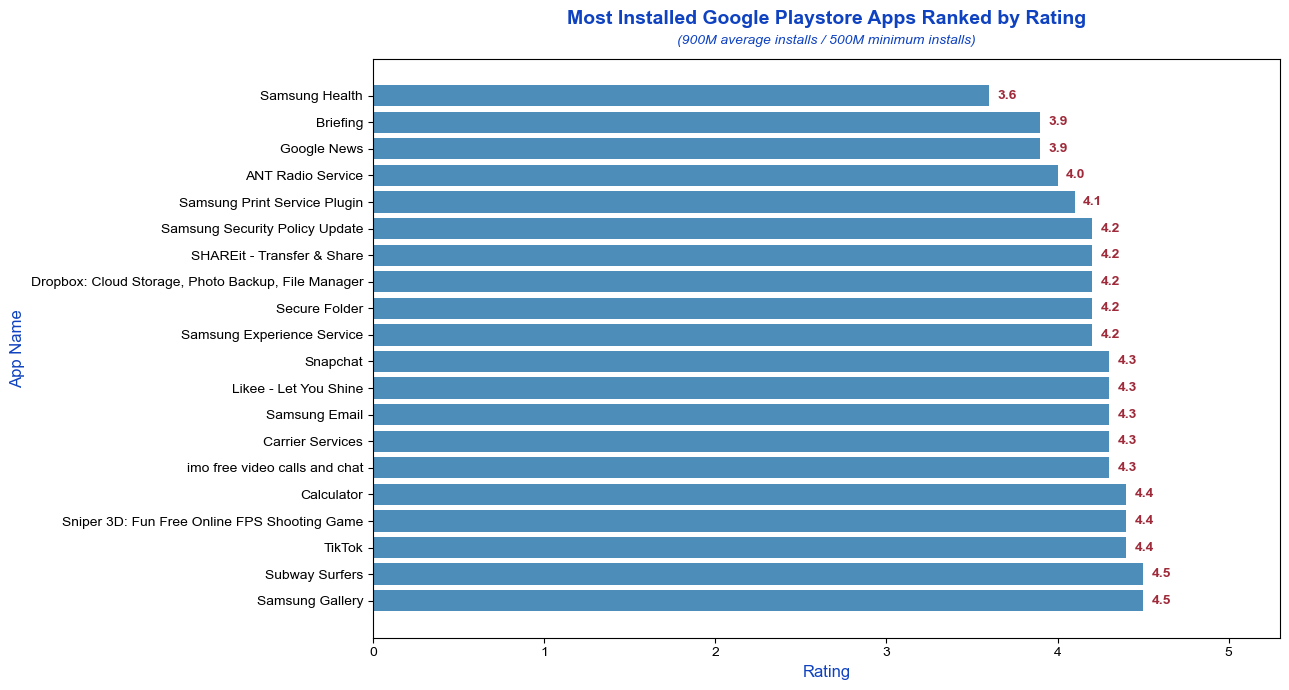

In [95]:
plt.rcParams['font.sans-serif'] = ['Arial']

app_names = most_installed['AppName']
ratings = most_installed['Rating']

plt.figure(figsize=(13, 7))

plt.barh(app_names, ratings, color='#4D8DBA')
plt.gca().invert_yaxis()
plt.xlim(0, 5.3)

plt.xlabel('Rating', fontsize=12, color='#0F42C0')
plt.ylabel('App Name', fontsize=12, color='#0F42C0')

# 1. Main Title centered over the plot box
plt.title('Most Installed Google Playstore Apps Ranked by Rating',
          fontname='Arial',
          fontsize=14,
          fontweight='bold',
          color='#0F42C0',
          pad=25)  # Creates vertical padding between title and chart top

# 2. Subtitle centered over the plot box using axes coordinates (0.5 = middle)
plt.gca().text(0.5, 1.02, '(900M average installs / 500M minimum installs)',
               transform=plt.gca().transAxes,
               ha='center', va='bottom',
               fontname='Arial',
               fontsize=10,
               fontstyle='italic',
               color='#0F42C0')

# Add bar labels
for i, value in enumerate(ratings):
    plt.text(value + 0.05, i, f'{value:.1f}', va='center',
             fontname='Arial', fontsize=10, fontweight='bold', color='#9E2A3A')

plt.tight_layout()
plt.show()

### 4.4_Objective 4: Identify the content rating of the top 100 most installed apps

In [96]:
# top 100 most installed apps
top_100_most_installed = top_100_most_installed = applications.nlargest(100, 'Installs')

In [97]:
top_100_most_installed['ContentRating'].unique()

array(['Everyone 10+', 'Teen', 'Everyone', 'Mature 17+'], dtype=object)

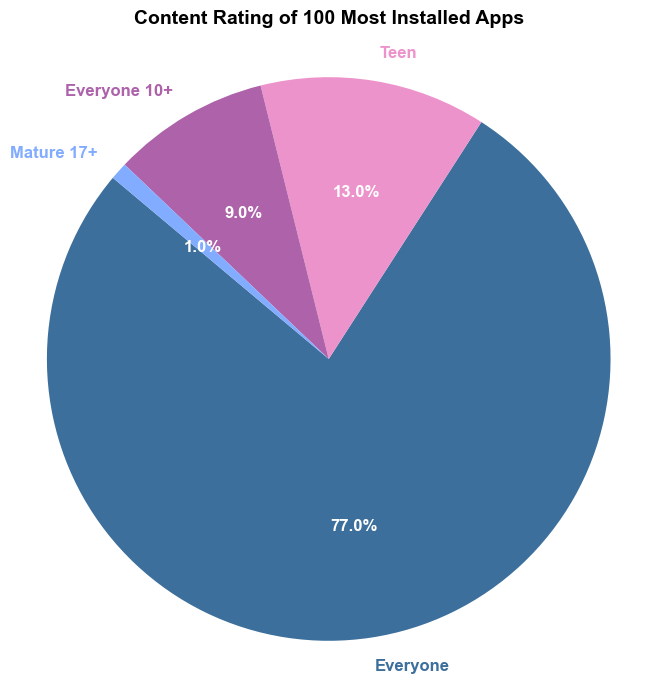

In [98]:
# Extract data
data = top_100_most_installed['ContentRating'].value_counts()
labels = data.index
values = data.values

# Define custom hex colors
custom_colors = ['#3C6F9C', '#ED93CB', '#AD62AA', '#82ACFF']

plt.figure(figsize=(8, 8))

# Capture wedges, label texts, and percentage autotexts
wedges, texts, autotexts = plt.pie(
    values,
    labels=labels,
    colors=custom_colors[:len(labels)],
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 12},
    wedgeprops={'linewidth': 0, 'edgecolor': 'none'}
)

# Set each label's color to match its slice color and make it bold
for i, text in enumerate(texts):
    text.set_color(custom_colors[i])
    text.set_fontweight('bold')

# Style percentage numbers inside the slices
plt.setp(autotexts, color='white', fontweight='bold', fontsize=12)

plt.title('Content Rating of 100 Most Installed Apps', fontsize=14, fontweight='bold', pad=20)
plt.axis('equal')
plt.show()